In [1]:
from pathlib import Path
from urllib.parse import urlparse
import csv
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# ---- Paths (relative to the project root) ----
RAW_PATH = Path("C:\\Users\\BHUMIKA.G\\Multimodal\\data\\raw\\PhiUSIIL_Phishing_URL_Dataset.csv")
PROCESSED_DIR = Path("data/processed")
OUTPUT_PATH = Path("C:\\Users\\BHUMIKA.G\\Multimodal\\data\\processed\\url_cleaned.csv")

# ---- Optional manual overrides ----
URL_COLUMN_OVERRIDE = None       # e.g. "URL"
TARGET_COLUMN_OVERRIDE = None    # e.g. "label"

# ---- Inspection settings ----
RANDOM_STATE = 42
NEAR_CONSTANT_THRESHOLD = 0.99

PLACEHOLDERS = [
    "na", "n/a", "nan", "null", "none", "nil", "?",
    "-", "--", "unknown", "undefined", "missing",
    "#n/a", "not available"
]

# ---- Cleaning strategy settings ----
# Conflicting labels for the same URL:
# "drop_all" -> remove all records for that URL
# "keep_all" -> retain all records and report the conflict
CONFLICTING_LABEL_STRATEGY = "drop_all"

# Duplicate URLs with the same label:
# "keep_first" -> retain the first occurrence
# "keep_all" -> retain all occurrences
SAME_LABEL_URL_STRATEGY = "keep_first"

# Expected label meanings from the dataset documentation.
# These settings check labels but do not automatically rewrite them.
EXPECTED_LABEL_MEANING = {
    0: "phishing",
    1: "legitimate"
}

DROP_UNEXPECTED_LABELS = False

assert CONFLICTING_LABEL_STRATEGY in {"drop_all", "keep_all"}
assert SAME_LABEL_URL_STRATEGY in {"keep_first", "keep_all"}

# Only genuinely empty cells become NaN.
# Strings such as "NA" and "null" remain unchanged for inspection.
READ_KWARGS = {
    "low_memory": False,
    "keep_default_na": False,
    "na_values": [""]
}

# ---- Create processed folder and validate paths ----
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

assert OUTPUT_PATH.resolve() != RAW_PATH.resolve(), (
    "Output path must never equal the raw dataset path!"
)

assert PROCESSED_DIR.resolve() != RAW_PATH.parent.resolve(), (
    "Processed folder must differ from the raw folder!"
)

# ---- Cleaning log ----
cleaning_log = []
unresolved_notes = []


def log_step(
    step,
    column,
    rows_affected,
    rows_removed,
    action,
    reason
):
    """Record a cleaning decision for reproducibility."""
    cleaning_log.append({
        "step": step,
        "column": column,
        "rows_affected": int(rows_affected),
        "rows_removed": int(rows_removed),
        "action": action,
        "reason": reason,
    })

    print(
        f"[{step}] {action} | "
        f"column: {column} | "
        f"affected: {int(rows_affected):,} | "
        f"removed: {int(rows_removed):,}"
    )


# ---- Initial project and file checks ----
print("Working directory :", Path.cwd())
print("Raw file          :", RAW_PATH)
print("Output file       :", OUTPUT_PATH)
print("Processed folder exists:", PROCESSED_DIR.exists())

if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"Raw dataset not found: {RAW_PATH.resolve()}\n"
        "Check that the CSV file exists and that the working "
        "directory is the project root."
    )

if RAW_PATH.resolve() == OUTPUT_PATH.resolve():
    raise ValueError("Input and output paths must be different.")

print("\nInitial configuration completed successfully.")

Working directory : C:\Users\BHUMIKA.G\Multimodal\notebook
Raw file          : C:\Users\BHUMIKA.G\Multimodal\data\raw\PhiUSIIL_Phishing_URL_Dataset.csv
Output file       : C:\Users\BHUMIKA.G\Multimodal\data\processed\url_cleaned.csv
Processed folder exists: True

Initial configuration completed successfully.


In [2]:
# ---- Check whether the raw dataset exists ----
if not RAW_PATH.exists():
    csv_files = (
        sorted(str(p) for p in Path("data").rglob("*.csv"))
        if Path("data").exists()
        else []
    )

    raise FileNotFoundError(
        f"\nCould not find the raw dataset at: {RAW_PATH.resolve()}\n"
        f"Current working directory: {Path.cwd()}\n"
        "What to check:\n"
        "  1. Run this notebook from the PROJECT ROOT "
        "(the folder that contains the 'data' folder).\n"
        "  2. Make sure the file is named exactly "
        "'PhiUSIIL_Phishing_URL_Dataset.csv'.\n"
        "  3. Make sure it is inside 'data/raw/'.\n"
        f"CSV files found under 'data/': "
        f"{csv_files if csv_files else 'none'}"
    ) from None


# ---- Load the CSV with encoding fallback ----
# utf-8-sig also removes an invisible BOM character if present.
# Fall back to latin-1 if UTF-8 decoding fails.
used_encoding = "utf-8-sig"

try:
    df_raw = pd.read_csv(
        RAW_PATH,
        encoding=used_encoding,
        **READ_KWARGS
    )
except UnicodeDecodeError:
    used_encoding = "latin-1"

    df_raw = pd.read_csv(
        RAW_PATH,
        encoding=used_encoding,
        **READ_KWARGS
    )

print("Loaded with encoding:", used_encoding)


# ---- Read the original header to detect duplicate column names ----
with open(
    RAW_PATH,
    newline="",
    encoding=used_encoding
) as f:
    raw_header = next(csv.reader(f))


# ---- Capture raw-data fingerprints ----
# These values can be used later to verify that the source file
# has not been modified during the cleaning process.
raw_file_size = RAW_PATH.stat().st_size
raw_file_mtime = RAW_PATH.stat().st_mtime

raw_fingerprint = int(
    pd.util.hash_pandas_object(
        df_raw,
        index=True
    ).astype("uint64").sum()
)


# ---- Display dataset dimensions and column names ----
print(
    f"\nDimensions: {df_raw.shape[0]:,} rows "
    f"x {df_raw.shape[1]} columns"
)

print("\nColumn names:")
print(list(df_raw.columns))

Loaded with encoding: utf-8-sig

Dimensions: 235,795 rows x 56 columns

Column names:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'lab

In [3]:
# ---- Display the first 5 rows ----
print("First 5 rows:")
display(df_raw.head())


# ---- Display the last 5 rows ----
print("Last 5 rows:")
display(df_raw.tail())


# ---- Display a reproducible random sample of 5 rows ----
print(f"Random sample of 5 rows (random_state={RANDOM_STATE}):")
display(df_raw.sample(
    n=min(5, len(df_raw)),
    random_state=RANDOM_STATE
))

First 5 rows:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000,1.000,0.523,0.062,3,1,0,0,0.000,18,0.581,0,0.000,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µà¹‰ à¸‚à¹ˆà¸²à¸§à¸à¸µà¸¬à¸² à...,0.000,0.000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000,0.667,0.033,0.050,2,1,0,0,0.000,9,0.391,0,0.000,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.556,55.556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000,0.867,0.029,0.064,2,2,0,0,0.000,15,0.517,0,0.000,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.667,46.667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000,1.000,0.523,0.058,3,1,0,0,0.000,13,0.500,0,0.000,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medicine,0.000,0.000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000,1.000,0.080,0.059,3,1,0,0,0.000,20,0.606,0,0.000,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000,100.000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


Last 5 rows:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
235790,660997.txt,https://www.skincareliving.com,29,www.skincareliving.com,22,0,com,100.000,1.000,0.523,0.059,3,1,0,0,0.000,16,0.552,0,0.000,0,0,0,1,0.034,1,2007,9381,1,skincareliving,100.000,100.000,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,0,1,51,7,21,187,2,191,1
235791,77185.txt,https://www.winchester.gov.uk,28,www.winchester.gov.uk,21,0,uk,100.000,0.786,0.029,0.054,2,2,0,0,0.000,14,0.500,0,0.000,0,0,0,2,0.071,1,1081,348,1,winchestergov,0.000,0.000,1,0,1,0,0,1,0,0,0,1,1,1,0,0,1,0,0,50,1,7,88,0,31,1
235792,622132.txt,https://www.nononsensedesign.be,30,www.nononsensedesign.be,23,0,be,100.000,1.000,0.003,0.063,2,1,0,0,0.000,17,0.567,0,0.000,0,0,0,1,0.033,1,709,13277,1,nononsensedesign,100.000,100.000,1,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0,1,27,10,30,58,2,67,1
235793,7503962.txt,https://patient-cell-40f5.updatedlogmylogin.workers.dev/,55,patient-cell-40f5.updatedlogmylogin.workers.dev,47,0,dev,28.158,0.465,0.001,0.050,3,2,0,0,0.000,39,0.709,3,0.055,0,0,0,5,0.091,1,125,1807,1,patient-cell-40f5updatedlogmyloginworkers,0.000,0.000,0,0,1,0,0,0,0,2,0,0,1,1,1,0,0,0,0,0,0,3,0,0,0,0
235794,384822.txt,https://www.alternativefinland.com,33,www.alternativefinland.com,26,0,com,100.000,1.000,0.523,0.061,3,1,0,0,0.000,20,0.606,0,0.000,0,0,0,1,0.030,1,1038,3346,1,alternativefinland,100.000,100.000,0,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0,1,21,6,18,256,0,261,1


Random sample of 5 rows (random_state=42):


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
136221,827598.txt,https://www.northcm.ac.th,24,www.northcm.ac.th,17,0,th,100.000,0.800,0.001,0.064,2,2,0,0,0.000,10,0.417,0,0.000,0,0,0,2,0.083,1,999,457,1,norhcmac,0.000,0.000,1,0,1,0,0,1,0,5,0,1,1,1,0,0,0,0,1,47,3,4,69,7,115,1
56609,oph00308.txt,https://unitedmartialartscenters.com/at0/mygov/personal.html,59,unitedmartialartscenters.com,28,0,com,33.523,1.000,0.523,0.060,3,0,0,0,0.000,45,0.763,1,0.017,0,0,0,5,0.085,1,116,226,1,unitedmartialartscentersat0mygovpersonalhtm,0.000,0.000,1,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,1,0,2,0,0,0,1,0
46393,8112660.txt,https://email.mail1.onesignal.os.tc/c/ejwcz02untamqohvwmwoczwfbgw6uduohnspqd...,385,email.mail1.onesignal.os.tc,27,0,tc,3.199,0.458,0.000,0.034,2,3,0,0,0.000,302,0.784,51,0.132,0,0,0,24,0.062,1,14,393,1,emailmail1onesignaloscejwcz02untamqohvwmwoczwfbgw6uduohnspqdycugml7r66b3ikm_...,0.000,0.000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
129746,8135291.txt,http://uqr.to/1il1z,19,uqr.to,6,0,to,53.846,1.000,0.001,0.037,2,0,0,0,0.000,8,0.421,2,0.105,0,0,0,2,0.105,0,9,70,1,uqr1il1z,0.000,100.000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
131464,586561.txt,https://www.woolworthsrewards.com.au,35,www.woolworthsrewards.com.au,28,0,au,100.000,0.857,0.010,0.061,2,2,0,0,0.000,21,0.600,0,0.000,0,0,0,2,0.057,1,1213,14983,1,woolworthsrewrdscom,0.000,0.000,1,0,1,1,1,1,0,3,0,1,0,1,1,1,1,0,1,33,7,8,15,0,2,1


In [4]:
print("Data types:")
display(
    df_raw.dtypes.astype(str)
    .rename("dtype")
    .to_frame()
)


# ---- Calculate total memory usage ----
mem = df_raw.memory_usage(deep=True)

print(f"Total memory usage: {mem.sum() / 1024**2:,.1f} MB")


# ---- Display the 8 largest columns by memory usage ----
print("\nLargest columns by memory (MB):")

display(
    (
        mem.drop("Index", errors="ignore")
        .sort_values(ascending=False)
        .head(8)
        / 1024**2
    )
    .rename("MB")
    .to_frame()
)


# ---- Create a separate working copy ----
# All cleaning operations will be performed on `df`.
# The original DataFrame `df_raw` remains unchanged.
df = df_raw.copy()

print("\nWorking copy `df` created. Shape:", df.shape)

Data types:


,dtype
FILENAME,object
URL,object
URLLength,int64
Domain,object
DomainLength,int64
IsDomainIP,int64
TLD,object
URLSimilarityIndex,float64
CharContinuationRate,float64
TLDLegitimateProb,float64


Total memory usage: 166.2 MB

Largest columns by memory (MB):


,MB
URL,18.972
Domain,15.847
Title,14.601
FILENAME,13.363
TLD,11.640
NoOfEmptyRef,1.799
HasExternalFormSubmit,1.799
NoOfExternalRef,1.799



Working copy `df` created. Shape: (235795, 56)


In [5]:
# ---------- 3.1 Discover the schema ----------

URL_NAME_HINTS = {"url", "urls", "link", "website", "webpage"}

TARGET_NAME_HINTS = [
    "label", "target", "class", "is_phishing",
    "phishing", "result", "status", "y"
]


def find_url_column(frame):
    """Return the raw-URL column name, or None if no raw URLs are found."""

    # 1. Use the manual override if provided.
    if URL_COLUMN_OVERRIDE is not None:
        assert URL_COLUMN_OVERRIDE in frame.columns, (
            f"URL_COLUMN_OVERRIDE '{URL_COLUMN_OVERRIDE}' not found."
        )
        return URL_COLUMN_OVERRIDE

    # 2. Detect the URL column by its name.
    for c in frame.columns:
        if c.strip().lower() in URL_NAME_HINTS:
            return c

    # 3. Detect the URL column by examining its contents.
    pattern = r"(?i)^\s*(?:https?|ftp)://|^\s*www\."

    for c in frame.columns:
        if pd.api.types.is_numeric_dtype(frame[c]):
            continue

        sample = frame[c].dropna().astype(str).head(2000)

        if (
            len(sample)
            and sample.str.contains(pattern, regex=True).mean() > 0.5
        ):
            return c

    return None


def find_target_column(frame):
    """Return the name of the target-label column."""

    # 1. Use the manual override if provided.
    if TARGET_COLUMN_OVERRIDE is not None:
        assert TARGET_COLUMN_OVERRIDE in frame.columns, (
            f"TARGET_COLUMN_OVERRIDE '{TARGET_COLUMN_OVERRIDE}' not found."
        )
        return TARGET_COLUMN_OVERRIDE

    # 2. Match column names against common target-label names.
    lowered = {
        c.strip().lower(): c
        for c in frame.columns
    }

    for hint in TARGET_NAME_HINTS:
        if hint in lowered:
            return lowered[hint]

    raise ValueError(
        "Could not detect the target column automatically. "
        "Inspect the column list above and set "
        "TARGET_COLUMN_OVERRIDE in Section 1."
    )


# ---- Detect URL and target columns ----
URL_COL = find_url_column(df_raw)
TARGET_COL = find_target_column(df_raw)


# ---- Identify numeric and text/other columns ----
numeric_cols = [
    c for c in df_raw.columns
    if (
        pd.api.types.is_numeric_dtype(df_raw[c])
        and not pd.api.types.is_bool_dtype(df_raw[c])
    )
]

text_cols = [
    c for c in df_raw.columns
    if c not in numeric_cols
]


# ---- Display detected schema ----
print(
    "Detected URL column   :",
    URL_COL if URL_COL else "NONE (dataset has no raw URL column)"
)

print("Detected target column:", TARGET_COL)

print(
    f"Numeric columns: {len(numeric_cols)} | "
    f"Text/other columns: {len(text_cols)}"
)

print("Text/other columns   :", text_cols)


# ---- Determine dataset content type ----
other_text = [
    c for c in text_cols
    if c != URL_COL
]

if URL_COL and len(numeric_cols) > 1:
    content_type = "BOTH raw URLs and engineered (numeric) features"

elif URL_COL:
    content_type = "raw URLs only"

else:
    content_type = "engineered features only (no raw URL column)"


print("\nDataset content type :", content_type)
print("Other text columns   :", other_text)

Detected URL column   : URL
Detected target column: label
Numeric columns: 51 | Text/other columns: 5
Text/other columns   : ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']

Dataset content type : BOTH raw URLs and engineered (numeric) features
Other text columns   : ['FILENAME', 'Domain', 'TLD', 'Title']


In [6]:
# ---- Dataset dimensions ----
print(
    f"Total rows: {df_raw.shape[0]:,} | "
    f"Total columns: {df_raw.shape[1]}"
)


# ---- Inspect column names from the original CSV header ----
header_series = pd.Series(raw_header)

dup_col_names = header_series[
    header_series.duplicated(keep=False)
].tolist()

odd_col_names = [
    c for c in raw_header
    if c != c.strip()
]

print(
    "Duplicate column names in the CSV header:",
    dup_col_names if dup_col_names else "None"
)

print(
    "Column names with leading/trailing spaces:",
    odd_col_names if odd_col_names else "None"
)


# ---- Calculate missing values before cleaning ----
# Saved for the final before/after comparison.
missing_before_raw = df_raw.isna().sum()


# ---- Build a comprehensive column summary ----
summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": missing_before_raw,
    "missing_%": (df_raw.isna().mean() * 100).round(3),
    "unique_values": df_raw.nunique(dropna=True),
})


# ---- Display the column summary ----
print("\nColumn summary (dtype, missing values, unique values):")
display(summary)


# ---- Report missing values ----
if missing_before_raw.sum() == 0:
    print("\nNo genuine missing values (NaN) found in any column.")

else:
    print(
        "\nColumns with missing values:",
        int((missing_before_raw > 0).sum())
    )

    display(
        summary[summary["missing"] > 0]
        .sort_values("missing", ascending=False)
    )

Total rows: 235,795 | Total columns: 56
Duplicate column names in the CSV header: None
Column names with leading/trailing spaces: None

Column summary (dtype, missing values, unique values):


,dtype,non_null,missing,missing_%,unique_values
FILENAME,object,235795,0,0.000,235795
URL,object,235795,0,0.000,235370
URLLength,int64,235795,0,0.000,482
Domain,object,235795,0,0.000,220086
DomainLength,int64,235795,0,0.000,101
IsDomainIP,int64,235795,0,0.000,2
TLD,object,235795,0,0.000,695
URLSimilarityIndex,float64,235795,0,0.000,36360
CharContinuationRate,float64,235795,0,0.000,898
TLDLegitimateProb,float64,235795,0,0.000,465



No genuine missing values (NaN) found in any column.


In [7]:
# ---------- 3.3 Empty strings, whitespace-only strings and placeholder text ----------

def text_quality_report(frame, cols):
    """
    For each text column, count:
    - Empty strings
    - Whitespace-only strings
    - Leading/trailing whitespace
    - Placeholder-like text
    - Genuine missing values (NaN)
    """
    rows = []

    for c in cols:
        values = frame[c].dropna().astype(str)
        stripped = values.str.strip()

        rows.append({
            "column": c,
            "missing_NaN": int(frame[c].isna().sum()),
            "empty_string": int((values == "").sum()),
            "whitespace_only": int(
                ((stripped == "") & (values != "")).sum()
            ),
            "leading/trailing_whitespace": int(
                (values != stripped).sum()
            ),
            "placeholder_like": int(
                stripped.str.lower().isin(PLACEHOLDERS).sum()
            ),
        })

    return pd.DataFrame(rows).set_index("column")


# ---- Generate the text-quality report ----
text_report = text_quality_report(df_raw, text_cols)

print(
    "Text-quality report "
    "(placeholders are only COUNTED here; nothing is converted):"
)

display(text_report)


# ---- Display examples of placeholder-like values ----
# These values are inspected but not modified.
for c in text_cols:
    vals = df_raw[c].dropna().astype(str)

    hits = vals[
        vals.str.strip().str.lower().isin(PLACEHOLDERS)
    ]

    if len(hits):
        print(
            f"\nExamples of placeholder-like values in '{c}':"
        )

        print(
            hits.value_counts()
            .head(5)
            .to_string()
        )

Text-quality report (placeholders are only COUNTED here; nothing is converted):


,missing_NaN,empty_string,whitespace_only,leading/trailing_whitespace,placeholder_like
column,,,,,
FILENAME,0,0,0,0,0
URL,0,0,0,0,0
Domain,0,0,0,0,0
TLD,0,0,0,0,19
Title,0,0,0,1,6



Examples of placeholder-like values in 'TLD':
TLD
na    19

Examples of placeholder-like values in 'Title':
Title
na     5
nil    1


In [8]:
# ---------- 3.4 Infinite values and suspicious data types ----------

# ---- Check for infinite values in numeric columns ----
inf_counts = pd.Series({
    c: int(np.isinf(df_raw[c]).sum())
    for c in numeric_cols
})

inf_counts = inf_counts[inf_counts > 0]

print(
    "Infinite values in numeric columns:",
    "None" if inf_counts.empty else ""
)

if not inf_counts.empty:
    display(
        inf_counts.rename("infinite_values").to_frame()
    )


# ---- Identify text columns that look mostly numeric ----
# Such columns may have been loaded as text because of a few
# non-numeric or malformed values.
numeric_like_text = []

for c in text_cols:
    if c == URL_COL:
        continue

    vals = (
        df_raw[c]
        .dropna()
        .astype(str)
        .str.strip()
    )

    if len(vals) == 0:
        continue

    share = (
        pd.to_numeric(vals, errors="coerce")
        .notna()
        .mean()
    )

    if share >= 0.9:
        numeric_like_text.append(
            (c, round(float(share) * 100, 2))
        )


print(
    "\nText columns that look numeric "
    "(column, % numeric-looking):"
)

print(
    numeric_like_text
    if numeric_like_text
    else "None"
)


# ---- Identify binary-like numeric columns ----
# Columns containing only 0 and 1 may represent binary flags.
binary_like = [
    c for c in numeric_cols
    if set(df_raw[c].dropna().unique()) <= {0, 1}
]

print(
    f"\nNumeric columns containing only 0/1 values "
    f"(flag-like): {len(binary_like)}"
)

print(binary_like)


# ---- Check the target column's data type ----
# A floating-point target is not necessarily an error;
# its labels will be validated in Section 8.
if pd.api.types.is_float_dtype(df_raw[TARGET_COL]):
    print(
        f"\nNote: target '{TARGET_COL}' is stored as float; "
        "it will be checked in Section 8."
    )

Infinite values in numeric columns: None

Text columns that look numeric (column, % numeric-looking):
None

Numeric columns containing only 0/1 values (flag-like): 20
['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'label']


In [9]:
# ---------- 3.5 Constant and near-constant columns ----------

const_rows = []

for c in df_raw.columns:
    freq = df_raw[c].value_counts(
        dropna=False,
        normalize=True
    )

    const_rows.append({
        "column": c,
        "unique_incl_NaN": int(len(freq)),
        "most_common_value": str(freq.index[0])[:40],
        "most_common_share_%": float(freq.iloc[0]) * 100
    })


# ---- Create the constant-column summary ----
const_df = pd.DataFrame(const_rows).set_index("column")


# ---- Identify constant columns ----
constant_cols = const_df.index[
    const_df["unique_incl_NaN"] <= 1
].tolist()


# ---- Identify near-constant columns ----
near_constant_cols = const_df.index[
    (const_df["unique_incl_NaN"] > 1)
    & (
        const_df["most_common_share_%"]
        >= NEAR_CONSTANT_THRESHOLD * 100
    )
].tolist()


# ---- Display results ----
print(
    "Constant columns:",
    constant_cols if constant_cols else "None"
)

print(
    f"Near-constant columns "
    f"(>= {NEAR_CONSTANT_THRESHOLD:.0%} same value):",
    near_constant_cols if near_constant_cols else "None"
)


# ---- Display details for flagged columns ----
flagged_cols = constant_cols + near_constant_cols

if flagged_cols:
    display(const_df.loc[flagged_cols])


print(
    "\nNOTE: Such columns are only REPORTED. "
    "Removing columns is feature selection "
    "(a later notebook)."
)

Constant columns: None
Near-constant columns (>= 99% same value): ['IsDomainIP', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfAmpersandInURL']


,unique_incl_NaN,most_common_value,most_common_share_%
column,,,
IsDomainIP,2,0,99.729
HasObfuscation,2,0,99.794
NoOfObfuscatedChar,20,0,99.794
ObfuscationRatio,146,0.0,99.794
NoOfAmpersandInURL,31,0,99.624



NOTE: Such columns are only REPORTED. Removing columns is feature selection (a later notebook).


In [10]:
# ---------- 3.6 Duplicates ----------

# ---- Check exact duplicate rows ----
# A row is an exact duplicate when every column matches another row.
dup_rows_before = int(df_raw.duplicated().sum())

row_count = len(df_raw)
dup_percentage = (
    dup_rows_before / row_count * 100
    if row_count > 0
    else 0.0
)

print(
    f"Exact duplicate rows (every column identical): "
    f"{dup_rows_before:,} "
    f"({dup_percentage:.3f}% of rows)"
)


# ---- Check duplicate URLs, if a URL column exists ----
if URL_COL:
    url_series = df_raw[URL_COL]

    # All rows belonging to repeated, non-missing URLs.
    dup_url_rows_before = int(
        (
            url_series.duplicated(keep=False)
            & url_series.notna()
        ).sum()
    )

    # Number of extra copies beyond the first occurrence.
    dup_url_extra_before = int(
        (
            url_series.duplicated(keep="first")
            & url_series.notna()
        ).sum()
    )

    # Number of distinct non-missing URLs appearing more than once.
    n_dup_url_values = int(
        url_series[
            url_series.duplicated(keep=False)
            & url_series.notna()
        ].nunique()
    )

    print(
        f"Rows whose URL appears more than once        : "
        f"{dup_url_rows_before:,}"
    )

    print(
        f"Distinct URLs that are repeated              : "
        f"{n_dup_url_values:,}"
    )

    print(
        f"'Extra' copies (rows beyond the first of each): "
        f"{dup_url_extra_before:,}"
    )

else:
    # No raw URL column was detected.
    dup_url_rows_before = 0
    dup_url_extra_before = 0

    print(
        "No URL column -> duplicate-URL inspection skipped."
    )

Exact duplicate rows (every column identical): 0 (0.000% of rows)
Rows whose URL appears more than once        : 850
Distinct URLs that are repeated              : 425
'Extra' copies (rows beyond the first of each): 425


Target column: 'label' | dtype: int64


,count,percent
label,,
0,100945,42.810
1,134850,57.190


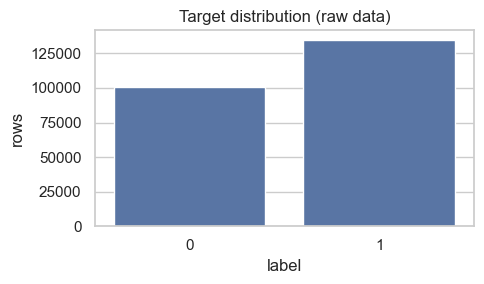

In [11]:
# ---------- 3.7 Target-label distribution ----------

def label_distribution(series):
    """Return label counts and percentages, including missing labels."""
    counts = series.value_counts(
        dropna=False
    ).sort_index()

    return pd.DataFrame({
        "count": counts,
        "percent": (
            counts / counts.sum() * 100
        ).round(3)
    })


def plot_label_distribution(series, title):
    """Plot the distribution of target labels."""
    counts = series.value_counts(
        dropna=False
    ).sort_index()

    labels = [str(i) for i in counts.index]

    fig, ax = plt.subplots(figsize=(5, 3))

    sns.barplot(
        x=labels,
        y=counts.to_numpy(),
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel(TARGET_COL)
    ax.set_ylabel("rows")

    plt.tight_layout()
    plt.show()


# ---- Display target-column information ----
print(
    f"Target column: '{TARGET_COL}' | "
    f"dtype: {df_raw[TARGET_COL].dtype}"
)


# ---- Display label counts and percentages ----
display(
    label_distribution(df_raw[TARGET_COL])
)


# ---- Visualize the raw target distribution ----
plot_label_distribution(
    df_raw[TARGET_COL],
    "Target distribution (raw data)"
)

In [12]:
# ---------- 3.8 Categorical / text columns: unique values and frequencies ----------

# ---- Inspect text columns other than the raw URL column ----
for c in other_text:
    n_unique = df_raw[c].nunique()

    print(f"\n=== '{c}' ({n_unique:,} unique values) ===")

    top = df_raw[c].value_counts(dropna=False)

    # Show all values when there are 20 or fewer unique values.
    # Otherwise, display only the 10 most frequent values.
    shown = top if n_unique <= 20 else top.head(10)

    display(
        pd.DataFrame({
            "count": shown,
            "percent": (
                shown / len(df_raw) * 100
            ).round(3)
        })
    )

    if n_unique > 20:
        print("(only the 10 most frequent values are shown)")


# ---- Inspect the raw URL column, if available ----
if URL_COL:
    print(f"\n=== '{URL_COL}' (raw URL) ===")

    print(
        f"Unique URLs: {df_raw[URL_COL].nunique():,} "
        f"of {df_raw[URL_COL].notna().sum():,} non-missing"
    )

    print("URL length (characters):")

    display(
        df_raw[URL_COL]
        .dropna()
        .astype(str)
        .str.len()
        .describe()
        .to_frame("URL length")
    )


=== 'FILENAME' (235,795 unique values) ===


,count,percent
FILENAME,,
521848.txt,1,0.000
96605.txt,1,0.000
oph08639.txt,1,0.000
8024072.txt,1,0.000
8014599.txt,1,0.000
439573.txt,1,0.000
492386.txt,1,0.000
7957102.txt,1,0.000
785434.txt,1,0.000


(only the 10 most frequent values are shown)

=== 'Domain' (220,086 unique values) ===


,count,percent
Domain,,
ipfs.io,1197,0.508
docs.google.com,526,0.223
mail.deliverylifesupport.com,370,0.157
cloudflare-ipfs.com,359,0.152
storageapi.fleek.co,318,0.135
gateway.pinata.cloud,275,0.117
gateway.ipfs.io,249,0.106
ipfs.litnet.work,223,0.095
cf-ipfs.com,190,0.081


(only the 10 most frequent values are shown)

=== 'TLD' (695 unique values) ===


,count,percent
TLD,,
com,112554,47.734
org,18793,7.970
net,7097,3.010
app,6508,2.760
uk,6395,2.712
co,5422,2.299
io,4201,1.782
de,3996,1.695
ru,3875,1.643


(only the 10 most frequent values are shown)

=== 'Title' (197,874 unique values) ===


,count,percent
Title,,
0,32719,13.876
#NAME?,21,0.009
65gfgfgfgfg4g4gblogspot?m=1,12,0.005
gov,11,0.005
info-update-sucreeblogspot,10,0.004
u,9,0.004
security-page-community-standardsblogspot,9,0.004
myip,7,0.003
package2021blogspot,7,0.003


(only the 10 most frequent values are shown)

=== 'URL' (raw URL) ===
Unique URLs: 235,370 of 235,795 non-missing
URL length (characters):


,URL length
count,"235,795.000"
mean,35.367
std,41.214
min,14.000
25%,24.000
50%,28.000
75%,35.000
max,"6,097.000"


In [13]:
display(
    df_raw[numeric_cols]
    .replace([np.inf, -np.inf], np.nan)
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
URLLength,"235,795.000",34.573,41.314,13.000,23.000,27.000,34.000,"6,097.000"
DomainLength,"235,795.000",21.470,9.151,4.000,16.000,20.000,24.000,110.000
IsDomainIP,"235,795.000",0.003,0.052,0.000,0.000,0.000,0.000,1.000
URLSimilarityIndex,"235,795.000",78.431,28.976,0.156,57.025,100.000,100.000,100.000
CharContinuationRate,"235,795.000",0.846,0.217,0.000,0.680,1.000,1.000,1.000
TLDLegitimateProb,"235,795.000",0.260,0.252,0.000,0.006,0.080,0.523,0.523
URLCharProb,"235,795.000",0.056,0.011,0.001,0.051,0.058,0.063,0.091
TLDLength,"235,795.000",2.764,0.600,2.000,2.000,3.000,3.000,13.000
NoOfSubDomain,"235,795.000",1.165,0.601,0.000,1.000,1.000,1.000,10.000
HasObfuscation,"235,795.000",0.002,0.045,0.000,0.000,0.000,0.000,1.000


In [14]:
# ---------- Section 4: Quality assessment table ----------

issues = []


def add_issue(issue, column, rows, decision, why):
    """Add a data-quality issue when at least one row is affected."""
    if int(rows) > 0:
        issues.append({
            "issue": issue,
            "column": column,
            "rows_affected": int(rows),
            "decision": decision,
            "justification": why
        })


# --- Missing values ---
for col, n in missing_before_raw[
    missing_before_raw > 0
].items():

    if col == TARGET_COL:
        add_issue(
            "Missing target label",
            col,
            n,
            "REMOVE rows",
            "A supervised model needs a known label; guessing a "
            "label would invent ground truth."
        )

    elif col == URL_COL:
        add_issue(
            "Missing URL",
            col,
            n,
            "REMOVE rows",
            "A record without a URL cannot be used by a URL detector "
            "or by later URL feature extraction."
        )

    else:
        add_issue(
            "Missing feature value",
            col,
            n,
            "PRESERVE as NaN",
            "Missingness can itself be informative. Filling now "
            "(before the train/test split) could cause leakage; "
            "imputation belongs in the modelling pipeline."
        )


# --- Empty, whitespace-only, and placeholder text ---
for col, r in text_report.iterrows():

    is_url = col == URL_COL

    # Empty strings
    add_issue(
        "Empty string",
        col,
        r["empty_string"],
        "REMOVE rows" if is_url else "PRESERVE",
        "An empty URL is unusable."
        if is_url
        else "An empty text field may be a genuine value, "
             "such as a page with no title."
    )

    # Whitespace-only strings
    add_issue(
        "Whitespace-only string",
        col,
        r["whitespace_only"],
        "REMOVE rows" if is_url else "PRESERVE",
        "A blank URL is unusable."
        if is_url
        else "Blank text may be real page content; "
             "it is not automatically treated as missing."
    )

    # Leading/trailing whitespace, excluding empty and
    # whitespace-only strings to avoid double-counting.
    ws_only_or_empty = (
        r["whitespace_only"] + r["empty_string"]
    )

    add_issue(
        "Leading/trailing whitespace",
        col,
        max(
            r["leading/trailing_whitespace"]
            - ws_only_or_empty,
            0
        ),
        "CORRECT (trim)" if is_url else "PRESERVE",
        "Surrounding whitespace is a collection artefact, "
        "not part of a URL; trimming removes it."
        if is_url
        else "Free-text fields are left untouched."
    )

    # Placeholder-like text
    add_issue(
        "Placeholder-like text (e.g. 'NA', 'null')",
        col,
        r["placeholder_like"],
        "PRESERVE (review)",
        "Could be genuine content, such as a page titled "
        "'None' or a domain called 'na'; automatic conversion "
        "could be risky."
    )


# --- Duplicate rows and URLs ---
add_issue(
    "Exact duplicate rows",
    "(all columns)",
    dup_rows_before,
    "REMOVE extra copies",
    "Identical rows add no information and can leak between "
    "training and test sets."
)

if URL_COL:
    add_issue(
        "Duplicate URL values",
        URL_COL,
        dup_url_rows_before,
        "INVESTIGATE then handle (Section 6)",
        "The same URL may have conflicting labels or different "
        "features; each case requires a separate decision."
    )


# --- Infinite values ---
for col, n in inf_counts.items():
    add_issue(
        "Infinite value",
        col,
        n,
        "CORRECT (set to NaN)",
        "Infinity can break many ML algorithms; NaN preserves "
        "the invalid-value information for later handling."
    )


# --- Numeric-looking text columns ---
for col, share in numeric_like_text:
    n = int(
        pd.to_numeric(
            df_raw[col].dropna().astype(str).str.strip(),
            errors="coerce"
        ).notna().sum()
    )

    add_issue(
        "Numeric-looking text column",
        col,
        n,
        "PRESERVE (review later)",
        "Might be an identifier or a mis-typed numeric feature; "
        "changing data types is left to the feature notebook."
    )


# --- Constant and near-constant columns ---
for col in constant_cols:
    add_issue(
        "Constant column",
        col,
        len(df_raw),
        "PRESERVE (flag for feature selection)",
        "Carries no information, but dropping columns is "
        "feature selection and is outside this cleaning step."
    )

for col in near_constant_cols:
    affected = int(
        round(
            const_df.loc[col, "most_common_share_%"]
            / 100
            * len(df_raw)
        )
    )

    add_issue(
        "Near-constant column",
        col,
        affected,
        "PRESERVE (flag for feature selection)",
        "Rare values could still be useful phishing indicators; "
        "keep them for now."
    )


# --- Schema-level issues ---
if dup_col_names:
    add_issue(
        "Duplicate column names",
        str(dup_col_names),
        len(dup_col_names),
        "REPORT",
        "pandas may rename duplicate headers automatically; "
        "check the original CSV header manually."
    )

if odd_col_names:
    add_issue(
        "Column names with surrounding spaces",
        str(odd_col_names),
        len(odd_col_names),
        "REPORT",
        "Surrounding spaces can cause hard-to-find KeyErrors later."
    )


# --- Unexpected target labels ---
non_null_labels = df_raw[TARGET_COL].dropna()

unexpected_mask = ~non_null_labels.isin(
    list(EXPECTED_LABEL_MEANING.keys())
)

add_issue(
    "Unexpected label value",
    TARGET_COL,
    unexpected_mask.sum(),
    "REPORT (kept unless DROP_UNEXPECTED_LABELS=True)",
    "A value outside the expected encoding must be understood "
    "before it is removed or relabelled."
)


# --- Build and display the quality assessment table ---
issues_df = pd.DataFrame(issues)

if issues_df.empty:
    print(
        "No data-quality issues detected by the automatic checks."
    )
else:
    display(issues_df)

print(f"\nTotal distinct issues listed: {len(issues_df)}")

,issue,column,rows_affected,decision,justification
0,"Placeholder-like text (e.g. 'NA', 'null')",TLD,19,PRESERVE (review),"Could be genuine content, such as a page titled 'None' or a domain called 'n..."
1,Leading/trailing whitespace,Title,1,PRESERVE,Free-text fields are left untouched.
2,"Placeholder-like text (e.g. 'NA', 'null')",Title,6,PRESERVE (review),"Could be genuine content, such as a page titled 'None' or a domain called 'n..."
3,Duplicate URL values,URL,850,INVESTIGATE then handle (Section 6),The same URL may have conflicting labels or different features; each case re...
4,Near-constant column,IsDomainIP,235157,PRESERVE (flag for feature selection),Rare values could still be useful phishing indicators; keep them for now.
5,Near-constant column,HasObfuscation,235310,PRESERVE (flag for feature selection),Rare values could still be useful phishing indicators; keep them for now.
6,Near-constant column,NoOfObfuscatedChar,235310,PRESERVE (flag for feature selection),Rare values could still be useful phishing indicators; keep them for now.
7,Near-constant column,ObfuscationRatio,235310,PRESERVE (flag for feature selection),Rare values could still be useful phishing indicators; keep them for now.
8,Near-constant column,NoOfAmpersandInURL,234908,PRESERVE (flag for feature selection),Rare values could still be useful phishing indicators; keep them for now.



Total distinct issues listed: 9


In [15]:
# ---------- 5.1 Missing values BEFORE cleaning ----------

# ---- Count genuine missing values (NaN) in each column ----
missing_before_cleaning = df.isna().sum()

print(
    "Missing values (NaN) per column BEFORE cleaning "
    "(only columns with problems):"
)

if missing_before_cleaning.sum() == 0:
    print("-> none")

else:
    display(
        missing_before_cleaning[
            missing_before_cleaning > 0
        ]
        .rename("missing")
        .to_frame()
    )


# ---- Distinguish different types of text-quality issues ----
print(
    "\nNaN vs empty vs whitespace-only vs placeholder "
    "(text columns):"
)

display(
    text_quality_report(df, text_cols)[
        [
            "missing_NaN",
            "empty_string",
            "whitespace_only",
            "placeholder_like"
        ]
    ]
)

Missing values (NaN) per column BEFORE cleaning (only columns with problems):
-> none

NaN vs empty vs whitespace-only vs placeholder (text columns):


,missing_NaN,empty_string,whitespace_only,placeholder_like
column,,,,
FILENAME,0,0,0,0
URL,0,0,0,0
Domain,0,0,0,0
TLD,0,0,0,19
Title,0,0,0,6


In [16]:
# ---------- 5.2 Apply the missing-value decisions ----------

# (a) Remove rows with a missing target label
mask_missing_target = df[TARGET_COL].isna()
n = int(mask_missing_target.sum())

if n:
    df = df.loc[~mask_missing_target].copy()

log_step(
    "5a missing target",
    TARGET_COL,
    n,
    n,
    "Removed rows with missing target label",
    "Label is required for supervised learning and must not be invented."
)


# (b) Remove rows with a missing or blank URL
if URL_COL:
    url_str = df[URL_COL].astype("string")

    blank_url = (
        url_str.isna() | (url_str.str.strip() == "")
    ).fillna(True).to_numpy(dtype=bool)

    n = int(blank_url.sum())

    if n:
        df = df.loc[~blank_url].copy()

    log_step(
        "5b missing/blank URL",
        URL_COL,
        n,
        n,
        "Removed rows with missing, empty or whitespace-only URL",
        "URL feature extraction needs a URL."
    )

else:
    print("5b skipped: no URL column in this dataset.")


# (c) Replace infinite values in numeric columns with NaN
# This preserves the invalid-value information as missing data.
for c in numeric_cols:
    n = int(np.isinf(df[c]).sum())

    if n:
        df[c] = df[c].replace(
            [np.inf, -np.inf],
            np.nan
        )

        log_step(
            "5c infinite values",
            c,
            n,
            0,
            "Replaced +/-inf with NaN",
            "Infinity is invalid input for ML algorithms."
        )

if not any(
    e["step"] == "5c infinite values"
    for e in cleaning_log
):
    print("5c: no infinite values found.")


# (d) Preserve other missing values and placeholder-like text
print(
    "\n5d: remaining NaNs in other feature columns and "
    "placeholder-like text are PRESERVED "
    "(no imputation here)."
)

print(f"Rows now: {len(df):,}")


[5a missing target] Removed rows with missing target label | column: label | affected: 0 | removed: 0
[5b missing/blank URL] Removed rows with missing, empty or whitespace-only URL | column: URL | affected: 0 | removed: 0
5c: no infinite values found.

5d: remaining NaNs in other feature columns and placeholder-like text are PRESERVED (no imputation here).
Rows now: 235,795


In [17]:
# ---------- 5.3 Missing values AFTER cleaning (before vs after) ----------

# ---- Count remaining missing values ----
missing_after_5 = df.isna().sum()


# ---- Compare missing values before and after cleaning ----
compare_missing = pd.DataFrame({
    "before_cleaning": missing_before_cleaning,
    "after_cleaning": missing_after_5
})

# Display columns that had missing values before or after cleaning.
changed = compare_missing[
    (compare_missing > 0).any(axis=1)
]

if changed.empty:
    print("No missing values before or after cleaning.")
else:
    display(changed)


# ---- Report remaining placeholder-like text ----
# Placeholder strings are deliberately preserved.
print("Remaining placeholder-like text (kept on purpose):")

placeholder_report = text_quality_report(
    df,
    [c for c in text_cols if c in df.columns]
)[["placeholder_like"]]

display(
    placeholder_report.query("placeholder_like > 0")
)

No missing values before or after cleaning.
Remaining placeholder-like text (kept on purpose):


,placeholder_like
column,
TLD,19
Title,6


In [18]:
# ---------- 6.1 Exact duplicate rows ----------

# Identify duplicate rows, keeping the first occurrence.
exact_mask = df.duplicated(keep="first")
n_exact = int(exact_mask.sum())

print(
    f"Exact duplicate rows in the working data: {n_exact:,}"
)


# ---- Display examples before removing duplicates ----
if n_exact:
    print(
        "Example of duplicated records "
        "(first 3 rows that duplicate an earlier row):"
    )

    display(
        df.loc[exact_mask].head(3)
    )

    # Remove duplicate rows, preserving the first occurrence.
    df = df.loc[~exact_mask].copy()


# ---- Record the cleaning action ----
log_step(
    "6a exact duplicates",
    "(all columns)",
    n_exact,
    n_exact,
    "Removed exact duplicate rows (kept first)",
    "Identical records carry no extra information and can "
    "contribute to data leakage."
)

exact_dups_removed = n_exact

Exact duplicate rows in the working data: 0
[6a exact duplicates] Removed exact duplicate rows (kept first) | column: (all columns) | affected: 0 | removed: 0


In [19]:
# ---------- 6.2 Duplicate URLs: investigate before deciding ----------

conflicting_urls = set()

if not URL_COL:
    print("No URL column -> URL-duplicate handling skipped.")

else:
    # Create a comparison key by trimming surrounding whitespace.
    # The original URL column is not modified in this section.
    url_key = df[URL_COL].astype(str).str.strip()

    is_dup_url = url_key.duplicated(keep=False)

    print(
        f"Rows whose URL appears more than once: "
        f"{int(is_dup_url.sum()):,} "
        f"({url_key[is_dup_url].nunique():,} distinct URLs)"
    )

    if is_dup_url.any():
        # Select records belonging to repeated URL groups.
        dups = df.loc[is_dup_url]

        grouped = dups.groupby(
            url_key[is_dup_url],
            sort=False
        )

        # Count distinct target labels for each URL.
        label_nunique = grouped[TARGET_COL].nunique(
            dropna=False
        )

        # URLs associated with more than one target label.
        conflicting_urls = set(
            label_nunique.index[label_nunique > 1]
        )

        print(
            f"URLs with CONFLICTING labels: "
            f"{len(conflicting_urls):,}"
        )

        print(
            f"URLs repeated with the SAME label: "
            f"{int((label_nunique == 1).sum()):,}"
        )

        # ---- Identify columns that differ within duplicate-URL groups ----
        differing = (
            grouped.nunique(dropna=False) > 1
        ).sum()

        differing = differing[
            differing > 0
        ].sort_values(ascending=False)

        print(
            "\nColumns whose values differ inside duplicate-URL "
            "groups (column -> number of groups):"
        )

        if len(differing):
            display(
                differing.rename(
                    "groups_with_differences"
                ).to_frame()
            )
        else:
            display(
                pd.DataFrame({
                    "info": ["none"]
                })
            )

        # ---- Display examples of conflicting labels ----
        if conflicting_urls:
            example_urls = list(conflicting_urls)[:3]

            print(
                "Example of URLs with conflicting labels:"
            )

            cols_to_show = [
                c for c in [URL_COL, TARGET_COL]
                if c is not None
            ]

            display(
                df.loc[
                    url_key.isin(example_urls),
                    cols_to_show
                ].head(6)
            )

        # ---- Identify potential near-duplicates (information only) ----
        # Lowercasing and removing trailing slashes may identify
        # additional matches, but these are not automatically removed.
        loose_key = (
            url_key.str.lower()
            .str.rstrip("/")
        )

        extra_loose = (
            int(loose_key.duplicated().sum())
            - int(url_key.duplicated().sum())
        )

        print(
            "\n[info only] Extra near-duplicates that differ only "
            "by letter case or a trailing '/': "
            f"{max(extra_loose, 0):,} "
            "(NOT removed: they may be different pages)"
        )

Rows whose URL appears more than once: 850 (425 distinct URLs)
URLs with CONFLICTING labels: 0
URLs repeated with the SAME label: 425

Columns whose values differ inside duplicate-URL groups (column -> number of groups):


,groups_with_differences
FILENAME,425
URLLength,425
LetterRatioInURL,424
SpacialCharRatioInURL,407
NoOfOtherSpecialCharsInURL,289
DegitRatioInURL,250
URLCharProb,136
NoOfLettersInURL,129
Title,96
LargestLineLength,72



[info only] Extra near-duplicates that differ only by letter case or a trailing '/': 1,165 (NOT removed: they may be different pages)


In [20]:
conflicting_urls = set()

if not URL_COL:
    print("No URL column -> URL-duplicate handling skipped.")

else:
    # Create a comparison key by trimming surrounding whitespace.
    # The original URL column remains unchanged.
    url_key = df[URL_COL].astype(str).str.strip()

    is_dup_url = url_key.duplicated(keep=False)

    print(
        f"Rows whose URL appears more than once: "
        f"{int(is_dup_url.sum()):,} "
        f"({url_key[is_dup_url].nunique():,} distinct URLs)"
    )

    if is_dup_url.any():
        # Select rows belonging to repeated URL groups.
        dups = df.loc[is_dup_url]

        grouped = dups.groupby(
            url_key[is_dup_url],
            sort=False
        )

        # Count distinct target labels within each URL group.
        label_nunique = grouped[TARGET_COL].nunique(
            dropna=False
        )

        # Identify URLs associated with conflicting labels.
        conflicting_urls = set(
            label_nunique.index[label_nunique > 1]
        )

        print(
            f"URLs with CONFLICTING labels: "
            f"{len(conflicting_urls):,}"
        )

        print(
            f"URLs repeated with the SAME label: "
            f"{int((label_nunique == 1).sum()):,}"
        )

        # ---- Identify columns that differ within duplicate-URL groups ----
        differing = (
            grouped.nunique(dropna=False) > 1
        ).sum()

        differing = differing[
            differing > 0
        ].sort_values(ascending=False)

        print(
            "\nColumns whose values differ inside duplicate-URL "
            "groups (column -> number of groups):"
        )

        if len(differing):
            display(
                differing.rename(
                    "groups_with_differences"
                ).to_frame()
            )
        else:
            display(
                pd.DataFrame({"info": ["none"]})
            )

        # ---- Display examples of conflicting labels ----
        if conflicting_urls:
            example_urls = list(conflicting_urls)[:3]

            print(
                "Example of a URL with conflicting labels:"
            )

            cols_to_show = [
                c for c in [URL_COL, TARGET_COL]
                if c is not None
            ]

            display(
                df.loc[
                    url_key.isin(example_urls),
                    cols_to_show
                ].head(6)
            )

        # ---- Identify potential near-duplicates (information only) ----
        # Lowercasing and removing trailing slashes may identify
        # additional matches, but these records are not removed.
        loose_key = (
            url_key.str.lower()
            .str.rstrip("/")
        )

        extra_loose = (
            int(loose_key.duplicated().sum())
            - int(url_key.duplicated().sum())
        )

        print(
            "\n[info only] Extra near-duplicates that differ only "
            "by letter case or a trailing '/': "
            f"{max(extra_loose, 0):,} "
            "(NOT removed: they may be different pages)"
        )

Rows whose URL appears more than once: 850 (425 distinct URLs)
URLs with CONFLICTING labels: 0
URLs repeated with the SAME label: 425

Columns whose values differ inside duplicate-URL groups (column -> number of groups):


,groups_with_differences
FILENAME,425
URLLength,425
LetterRatioInURL,424
SpacialCharRatioInURL,407
NoOfOtherSpecialCharsInURL,289
DegitRatioInURL,250
URLCharProb,136
NoOfLettersInURL,129
Title,96
LargestLineLength,72



[info only] Extra near-duplicates that differ only by letter case or a trailing '/': 1,165 (NOT removed: they may be different pages)


In [21]:
# ---------- 6.3 Handle duplicate URLs according to the chosen strategy ----------

removed_conflicting = 0
removed_same_label = 0

if URL_COL:

    # ==========================================================
    # (A) Handle URLs with conflicting target labels
    # ==========================================================
    url_key = df[URL_COL].astype(str).str.strip()

    conflict_mask = url_key.isin(conflicting_urls)
    n_conf_rows = int(conflict_mask.sum())

    if CONFLICTING_LABEL_STRATEGY == "drop_all" and n_conf_rows:
        # Remove every record belonging to a conflicting URL.
        df = df.loc[~conflict_mask].copy()

        removed_conflicting = n_conf_rows

        action = (
            "Removed ALL records of URLs that have conflicting labels"
        )

    else:
        action = (
            "Kept records with conflicting labels "
            "(strategy = keep_all)"
        )

    log_step(
        "6b conflicting-label URLs",
        URL_COL,
        n_conf_rows,
        removed_conflicting,
        action,
        "The true label is ambiguous; contradictory labels "
        "would confuse the model and the evaluation."
    )

    if CONFLICTING_LABEL_STRATEGY == "keep_all" and n_conf_rows:
        unresolved_notes.append(
            f"{n_conf_rows:,} rows belong to URLs with "
            "conflicting labels (kept by choice)."
        )


    # ==========================================================
    # (B) Handle repeated URLs with the same target label
    # ==========================================================
    # Recalculate URL keys after the conflicting-label step.
    url_key = df[URL_COL].astype(str).str.strip()

    same_label_dup = (
        url_key.duplicated(keep="first")
        & ~url_key.isin(conflicting_urls)
    )

    n_same = int(same_label_dup.sum())

    if SAME_LABEL_URL_STRATEGY == "keep_first" and n_same:
        # Keep only the first occurrence of each URL.
        df = df.loc[~same_label_dup].copy()

        removed_same_label = n_same

        action = (
            "Removed repeated URLs with the same label "
            "(kept first occurrence)"
        )

    else:
        action = (
            "Kept repeated URLs with the same label "
            "(strategy = keep_all)"
        )

    log_step(
        "6c same-label duplicate URLs",
        URL_COL,
        n_same,
        removed_same_label,
        action,
        "Keeping one copy per URL helps prevent the same URL "
        "from appearing in both training and test sets."
    )

    if SAME_LABEL_URL_STRATEGY == "keep_all" and n_same:
        unresolved_notes.append(
            f"{n_same:,} repeated URLs (same label) kept; "
            "use a grouped split by URL later to avoid leakage."
        )

else:
    print("URL duplicate handling skipped: no URL column.")


# ==========================================================
# (C) Recalculate duplicate counts after cleaning
# ==========================================================
dup_rows_after_6 = int(df.duplicated().sum())

dup_url_rows_after_6 = (
    int(
        df[URL_COL]
        .astype(str)
        .str.strip()
        .duplicated(keep=False)
        .sum()
    )
    if URL_COL
    else 0
)


# ==========================================================
# (D) Display the duplicate-cleaning summary
# ==========================================================
print("\nDuplicate summary:")

duplicate_summary = pd.DataFrame(
    {
        "identified": [
            exact_dups_removed,
            len(conflicting_urls),
            n_same if URL_COL else 0
        ],
        "rows_removed": [
            exact_dups_removed,
            removed_conflicting,
            removed_same_label
        ]
    },
    index=[
        "exact duplicate rows",
        "conflicting-label URLs (identified = URLs, removed = rows)",
        "same-label repeated URLs"
    ]
)

display(duplicate_summary)

print(
    f"Exact duplicate rows remaining: "
    f"{dup_rows_after_6:,}"
)

print(
    f"Rows with a repeated URL remaining: "
    f"{dup_url_rows_after_6:,}"
)

print(f"Rows now: {len(df):,}")

[6b conflicting-label URLs] Kept records with conflicting labels (strategy = keep_all) | column: URL | affected: 0 | removed: 0
[6c same-label duplicate URLs] Removed repeated URLs with the same label (kept first occurrence) | column: URL | affected: 425 | removed: 425

Duplicate summary:


,identified,rows_removed
exact duplicate rows,0,0
"conflicting-label URLs (identified = URLs, removed = rows)",0,0
same-label repeated URLs,425,425


Exact duplicate rows remaining: 0
Rows with a repeated URL remaining: 0
Rows now: 235,370


In [22]:
# ---------- 7.2 The one correction: trim whitespace around the URL ----------

if URL_COL:
    trim_mask = (df[URL_COL] != df[URL_COL].str.strip()).to_numpy(dtype=bool)
    n_trim = int(trim_mask.sum())

    if n_trim:
        print("Examples before trimming:")
        display(df.loc[trim_mask, URL_COL].head(5).map(repr).to_frame())
        df[URL_COL] = df[URL_COL].str.strip()

    log_step(
        "7a trim URL whitespace",
        URL_COL,
        n_trim,
        0,
        "Removed leading/trailing whitespace from URL",
        "Whitespace around a URL is a collection artefact; every real URL component is preserved."
    )

    print(
        "Rows with surrounding whitespace remaining:",
        int((df[URL_COL] != df[URL_COL].str.strip()).sum())
    )
    print("Exact duplicate rows after trimming:", int(df.duplicated().sum()))



[7a trim URL whitespace] Removed leading/trailing whitespace from URL | column: URL | affected: 0 | removed: 0
Rows with surrounding whitespace remaining: 0
Exact duplicate rows after trimming: 0


In [23]:
# ---------- 7.3 Is the dataset's URL-length feature consistent with the URL text? (check only) ----------

url_length_mismatch = None

if URL_COL:

    def norm(name):
        return re.sub(r"[^a-z0-9]", "", name.lower())

    length_cols = [c for c in df.columns if norm(c) == "urllength"]

    if length_cols:
        lc = length_cols[0]
        actual = df[URL_COL].str.len()

        mismatch = df[lc].notna() & (actual != df[lc])
        url_length_mismatch = int(mismatch.sum())

        print(
            f"Column '{lc}' vs real length of '{URL_COL}': "
            f"{url_length_mismatch:,} mismatching rows"
        )

        if url_length_mismatch:
            tmp = pd.DataFrame({
                "URL": df.loc[mismatch, URL_COL],
                "dataset_value": df.loc[mismatch, lc],
                "real_length": actual[mismatch]
            })

            display(tmp.head(5))

            unresolved_notes.append(
                f"{url_length_mismatch:,} rows where '{lc}' differs "
                "from the actual URL length (not modified)."
            )

    else:
        print("No URL-length feature found; consistency check skipped.")

Column 'URLLength' vs real length of 'URL': 186,942 mismatching rows


,URL,dataset_value,real_length
0,https://www.southbankmosaics.com,31,32
1,https://www.uni-mainz.de,23,24
2,https://www.voicefmradio.co.uk,29,30
3,https://www.sfnmjournal.com,26,27
4,https://www.rewildingargentina.org,33,34


In [24]:
# ---------- 7.4 Validity of engineered numeric features (check only, nothing is modified) ----------

# These are NAME-BASED heuristics. They only flag suspicious values; they never change them.

validity_rows = []

for c in numeric_cols:
    if c == TARGET_COL:
        continue

    s = df[c]
    lname = c.lower()

    if lname.startswith("noof") or "length" in lname or "lineofcode" in lname:
        validity_rows.append((
            "negative value in a count/length-style column",
            c,
            int((s < 0).sum())
        ))

    if "ratio" in lname or "prob" in lname:
        validity_rows.append((
            "value outside 0-1 in a ratio/probability-style column",
            c,
            int(((s < 0) | (s > 1)).sum())
        ))

    if re.match(r"^(is|has)[A-Z]", c):
        validity_rows.append((
            "value not in {0,1} in an Is*/Has* flag column",
            c,
            int((~s.isin([0, 1]) & s.notna()).sum())
        ))

validity_df = pd.DataFrame(
    validity_rows,
    columns=["check", "column", "rows_failing"]
)

bad = validity_df[validity_df["rows_failing"] > 0]

if bad.empty:
    print(
        f"All {len(validity_df)} heuristic validity checks passed "
        "(no suspicious engineered values)."
    )
else:
    display(bad)

    for _, r in bad.iterrows():
        unresolved_notes.append(
            f"Column '{r['column']}': {r['rows_failing']:,} rows - "
            f"{r['check']} (not modified)."
        )

print("\nEngineered features are left exactly as provided by the dataset authors.")



All 29 heuristic validity checks passed (no suspicious engineered values).

Engineered features are left exactly as provided by the dataset authors.


Target column: 'label' | dtype: int64
Unique values: [0, 1]
Missing labels: 0


,count,percent
label,,
0,100520,42.707
1,134850,57.293



Expected encoding (UCI documentation - please verify): {0: 'phishing', 1: 'legitimate'}
Unexpected label values found : None
Expected labels absent in data: None

Class balance ratio (largest / smallest documented class): 1.34


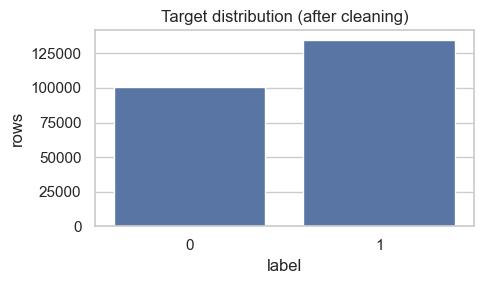

Label values were not renamed or re-encoded; their original meaning is preserved.


In [25]:
y = df[TARGET_COL]

print(f"Target column: '{TARGET_COL}' | dtype: {y.dtype}")
print("Unique values:", sorted(y.dropna().unique().tolist(), key=str))
print("Missing labels:", int(y.isna().sum()))

display(label_distribution(y))

# Compare with the documented encoding (check only)
present = set(y.dropna().unique().tolist())
expected = set(EXPECTED_LABEL_MEANING.keys())

unexpected_values = present - expected
missing_expected = expected - present

print("\nExpected encoding (UCI documentation - please verify):", EXPECTED_LABEL_MEANING)
print(
    "Unexpected label values found :",
    sorted(unexpected_values, key=str) if unexpected_values else "None"
)
print(
    "Expected labels absent in data:",
    sorted(missing_expected, key=str) if missing_expected else "None"
)

# Handle unexpected labels only if explicitly enabled by the user
if unexpected_values:
    bad_rows = ~y.isin(list(expected))
    n_bad = int(bad_rows.sum())

    if DROP_UNEXPECTED_LABELS:
        df = df.loc[~bad_rows].copy()

        log_step(
            "8a unexpected labels",
            TARGET_COL,
            n_bad,
            n_bad,
            f"Removed rows with labels {sorted(unexpected_values, key=str)}",
            "Labels outside the documented encoding (DROP_UNEXPECTED_LABELS=True)."
        )
    else:
        unresolved_notes.append(
            f"{n_bad:,} rows have unexpected label values "
            f"{sorted(unexpected_values, key=str)} (kept; investigate)."
        )
        print(
            f"WARNING: {n_bad:,} rows have unexpected labels. "
            "They are KEPT. Investigate before modelling."
        )

# Float -> int conversion, only if no value changes
y = df[TARGET_COL]

if (
    pd.api.types.is_float_dtype(y)
    and y.notna().all()
    and (y == y.round()).all()
):
    df[TARGET_COL] = y.astype("int64")

    log_step(
        "8b target dtype",
        TARGET_COL,
        len(df),
        0,
        "Converted target from float to int64 (values unchanged)",
        "Whole-number labels stored as floats were a by-product of missing values."
    )

# Class balance
dist = label_distribution(df[TARGET_COL])

# Only documented labels count for balance
dist_expected = dist.loc[dist.index.isin(list(expected))]

if len(dist_expected) >= 2:
    ratio = dist_expected["count"].max() / dist_expected["count"].min()
    print(
        f"\nClass balance ratio (largest / smallest documented class): {ratio:.2f}"
    )

plot_label_distribution(
    df[TARGET_COL],
    "Target distribution (after cleaning)"
)

print(
    "Label values were not renamed or re-encoded; "
    "their original meaning is preserved."
)

In [26]:
# ---------- Section 9: Final data-quality report ----------

df = df.reset_index(drop=True)

log_df = pd.DataFrame(cleaning_log)

original_shape = df_raw.shape
final_shape = df.shape

rows_removed_total = original_shape[0] - final_shape[0]

logged_removed = (
    int(log_df["rows_removed"].sum())
    if len(log_df)
    else 0
)

exact_removed = (
    int(
        log_df.loc[
            log_df["step"] == "6a exact duplicates",
            "rows_removed"
        ].sum()
    )
    if len(log_df)
    else 0
)

print("=" * 60)
print("FINAL DATA-QUALITY REPORT")
print("=" * 60)

print(
    f"Original shape            : "
    f"{original_shape[0]:,} rows x {original_shape[1]} columns"
)

print(
    f"Final shape               : "
    f"{final_shape[0]:,} rows x {final_shape[1]} columns"
)

print(
    f"Total rows removed        : "
    f"{rows_removed_total:,} "
    f"({rows_removed_total / original_shape[0] * 100:.3f}%)"
    if original_shape[0] > 0
    else "Total rows removed        : N/A (original dataset is empty)"
)

print(f"Exact duplicates removed  : {exact_removed:,}")

print("\nCleaning log (every change made):")

display(
    log_df
    if len(log_df)
    else pd.DataFrame({"info": ["No changes were necessary"]})
)

FINAL DATA-QUALITY REPORT
Original shape            : 235,795 rows x 56 columns
Final shape               : 235,370 rows x 56 columns
Total rows removed        : 425 (0.180%)
Exact duplicates removed  : 0

Cleaning log (every change made):


,step,column,rows_affected,rows_removed,action,reason
0,5a missing target,label,0,0,Removed rows with missing target label,Label is required for supervised learning and must not be invented.
1,5b missing/blank URL,URL,0,0,"Removed rows with missing, empty or whitespace-only URL",URL feature extraction needs a URL.
2,6a exact duplicates,(all columns),0,0,Removed exact duplicate rows (kept first),Identical records carry no extra information and can contribute to data leak...
3,6b conflicting-label URLs,URL,0,0,Kept records with conflicting labels (strategy = keep_all),The true label is ambiguous; contradictory labels would confuse the model an...
4,6c same-label duplicate URLs,URL,425,425,Removed repeated URLs with the same label (kept first occurrence),Keeping one copy per URL helps prevent the same URL from appearing in both t...
5,7a trim URL whitespace,URL,0,0,Removed leading/trailing whitespace from URL,Whitespace around a URL is a collection artefact; every real URL component i...


[7a trim URL whitespace] Removed leading/trailing whitespace from URL | column: URL | affected: 0 | removed: 0
Rows with surrounding whitespace remaining: 0
Exact duplicate rows after trimming: 0
Column 'URLLength' vs real length of 'URL': 186,942 mismatching rows


,URL,dataset_value,real_length
0,https://www.southbankmosaics.com,31,32
1,https://www.uni-mainz.de,23,24
2,https://www.voicefmradio.co.uk,29,30
3,https://www.sfnmjournal.com,26,27
4,https://www.rewildingargentina.org,33,34


All 29 heuristic validity checks passed (no suspicious engineered values).

Engineered features are left exactly as provided by the dataset authors.
Target column: 'label' | dtype: int64
Unique values: [0, 1]
Missing labels: 0


,count,percent
label,,
0,100520,42.707
1,134850,57.293



Expected encoding (UCI documentation - please verify): {0: 'phishing', 1: 'legitimate'}
Unexpected label values found : None
Expected labels absent in data: None

Class balance ratio (largest / smallest documented class): 1.34


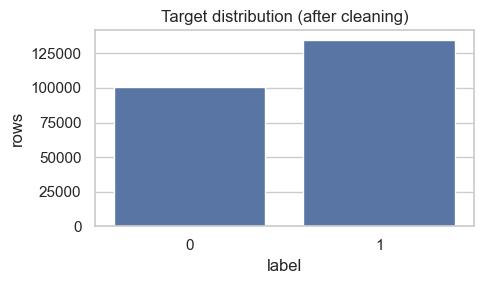

Label values were not renamed or re-encoded; their original meaning is preserved.
FINAL DATA-QUALITY REPORT
Original shape            : 235,795 rows x 56 columns
Final shape               : 235,370 rows x 56 columns
Total rows removed        : 425 (0.180%)
Exact duplicates removed  : 0

Cleaning log (every change made):


,step,column,rows_affected,rows_removed,action,reason
0,5a missing target,label,0,0,Removed rows with missing target label,Label is required for supervised learning and must not be invented.
1,5b missing/blank URL,URL,0,0,"Removed rows with missing, empty or whitespace-only URL",URL feature extraction needs a URL.
2,6a exact duplicates,(all columns),0,0,Removed exact duplicate rows (kept first),Identical records carry no extra information and can contribute to data leak...
3,6b conflicting-label URLs,URL,0,0,Kept records with conflicting labels (strategy = keep_all),The true label is ambiguous; contradictory labels would confuse the model an...
4,6c same-label duplicate URLs,URL,425,425,Removed repeated URLs with the same label (kept first occurrence),Keeping one copy per URL helps prevent the same URL from appearing in both t...
5,7a trim URL whitespace,URL,0,0,Removed leading/trailing whitespace from URL,Whitespace around a URL is a collection artefact; every real URL component i...
6,7a trim URL whitespace,URL,0,0,Removed leading/trailing whitespace from URL,Whitespace around a URL is a collection artefact; every real URL component i...


Unresolved / noted issues:
 1. 186,942 rows where 'URLLength' differs from the actual URL length (not modified).
 2. 186,942 rows where 'URLLength' differs from the actual URL length (not modified).
 3. Near-constant columns (candidates for feature selection): ['IsDomainIP', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfAmpersandInURL']
 4. Column 'TLD': 19 placeholder-like text values kept (could be genuine content).
 5. Column 'Title': 6 placeholder-like text values kept (could be genuine content).


In [27]:

# ---------- 7.2 The one correction: trim whitespace around the URL ----------

if URL_COL:
    trim_mask = (df[URL_COL] != df[URL_COL].str.strip()).to_numpy(dtype=bool)
    n_trim = int(trim_mask.sum())

    if n_trim:
        print("Examples before trimming:")
        display(df.loc[trim_mask, URL_COL].head(5).map(repr).to_frame())
        df[URL_COL] = df[URL_COL].str.strip()

    log_step(
        "7a trim URL whitespace",
        URL_COL,
        n_trim,
        0,
        "Removed leading/trailing whitespace from URL",
        "Whitespace around a URL is a collection artefact; every real URL component is preserved."
    )

    print(
        "Rows with surrounding whitespace remaining:",
        int((df[URL_COL] != df[URL_COL].str.strip()).sum())
    )
    print("Exact duplicate rows after trimming:", int(df.duplicated().sum()))



# ---------- 7.3 Is the dataset's URL-length feature consistent with the URL text? (check only) ----------

url_length_mismatch = None

if URL_COL:

    def norm(name):
        return re.sub(r"[^a-z0-9]", "", name.lower())

    length_cols = [c for c in df.columns if norm(c) == "urllength"]

    if length_cols:
        lc = length_cols[0]
        actual = df[URL_COL].str.len()

        mismatch = df[lc].notna() & (actual != df[lc])
        url_length_mismatch = int(mismatch.sum())

        print(
            f"Column '{lc}' vs real length of '{URL_COL}': "
            f"{url_length_mismatch:,} mismatching rows"
        )

        if url_length_mismatch:
            tmp = pd.DataFrame({
                "URL": df.loc[mismatch, URL_COL],
                "dataset_value": df.loc[mismatch, lc],
                "real_length": actual[mismatch]
            })

            display(tmp.head(5))

            unresolved_notes.append(
                f"{url_length_mismatch:,} rows where '{lc}' differs "
                "from the actual URL length (not modified)."
            )

    else:
        print("No URL-length feature found; consistency check skipped.")


# ---------- 7.4 Validity of engineered numeric features (check only, nothing is modified) ----------

# These are NAME-BASED heuristics. They only flag suspicious values; they never change them.

validity_rows = []

for c in numeric_cols:
    if c == TARGET_COL:
        continue

    s = df[c]
    lname = c.lower()

    if lname.startswith("noof") or "length" in lname or "lineofcode" in lname:
        validity_rows.append((
            "negative value in a count/length-style column",
            c,
            int((s < 0).sum())
        ))

    if "ratio" in lname or "prob" in lname:
        validity_rows.append((
            "value outside 0-1 in a ratio/probability-style column",
            c,
            int(((s < 0) | (s > 1)).sum())
        ))

    if re.match(r"^(is|has)[A-Z]", c):
        validity_rows.append((
            "value not in {0,1} in an Is*/Has* flag column",
            c,
            int((~s.isin([0, 1]) & s.notna()).sum())
        ))

validity_df = pd.DataFrame(
    validity_rows,
    columns=["check", "column", "rows_failing"]
)

bad = validity_df[validity_df["rows_failing"] > 0]

if bad.empty:
    print(
        f"All {len(validity_df)} heuristic validity checks passed "
        "(no suspicious engineered values)."
    )
else:
    display(bad)

    for _, r in bad.iterrows():
        unresolved_notes.append(
            f"Column '{r['column']}': {r['rows_failing']:,} rows - "
            f"{r['check']} (not modified)."
        )

print("\nEngineered features are left exactly as provided by the dataset authors.")



# ---------- Section 8: Target-label validation ----------

y = df[TARGET_COL]

print(f"Target column: '{TARGET_COL}' | dtype: {y.dtype}")
print("Unique values:", sorted(y.dropna().unique().tolist(), key=str))
print("Missing labels:", int(y.isna().sum()))

display(label_distribution(y))

# Compare with the documented encoding (check only)
present = set(y.dropna().unique().tolist())
expected = set(EXPECTED_LABEL_MEANING.keys())

unexpected_values = present - expected
missing_expected = expected - present

print("\nExpected encoding (UCI documentation - please verify):", EXPECTED_LABEL_MEANING)
print(
    "Unexpected label values found :",
    sorted(unexpected_values, key=str) if unexpected_values else "None"
)
print(
    "Expected labels absent in data:",
    sorted(missing_expected, key=str) if missing_expected else "None"
)

# Handle unexpected labels only if explicitly enabled by the user
if unexpected_values:
    bad_rows = ~y.isin(list(expected))
    n_bad = int(bad_rows.sum())

    if DROP_UNEXPECTED_LABELS:
        df = df.loc[~bad_rows].copy()

        log_step(
            "8a unexpected labels",
            TARGET_COL,
            n_bad,
            n_bad,
            f"Removed rows with labels {sorted(unexpected_values, key=str)}",
            "Labels outside the documented encoding (DROP_UNEXPECTED_LABELS=True)."
        )
    else:
        unresolved_notes.append(
            f"{n_bad:,} rows have unexpected label values "
            f"{sorted(unexpected_values, key=str)} (kept; investigate)."
        )
        print(
            f"WARNING: {n_bad:,} rows have unexpected labels. "
            "They are KEPT. Investigate before modelling."
        )

# Float -> int conversion, only if no value changes
y = df[TARGET_COL]

if (
    pd.api.types.is_float_dtype(y)
    and y.notna().all()
    and (y == y.round()).all()
):
    df[TARGET_COL] = y.astype("int64")

    log_step(
        "8b target dtype",
        TARGET_COL,
        len(df),
        0,
        "Converted target from float to int64 (values unchanged)",
        "Whole-number labels stored as floats were a by-product of missing values."
    )

# Class balance
dist = label_distribution(df[TARGET_COL])

# Only documented labels count for balance
dist_expected = dist.loc[dist.index.isin(list(expected))]

if len(dist_expected) >= 2:
    ratio = dist_expected["count"].max() / dist_expected["count"].min()
    print(
        f"\nClass balance ratio (largest / smallest documented class): {ratio:.2f}"
    )

plot_label_distribution(
    df[TARGET_COL],
    "Target distribution (after cleaning)"
)

print(
    "Label values were not renamed or re-encoded; "
    "their original meaning is preserved."
)


# ---------- Section 9: Final data-quality report ----------

df = df.reset_index(drop=True)

log_df = pd.DataFrame(cleaning_log)

original_shape = df_raw.shape
final_shape = df.shape

rows_removed_total = original_shape[0] - final_shape[0]

logged_removed = (
    int(log_df["rows_removed"].sum())
    if len(log_df)
    else 0
)

exact_removed = (
    int(
        log_df.loc[
            log_df["step"] == "6a exact duplicates",
            "rows_removed"
        ].sum()
    )
    if len(log_df)
    else 0
)

print("=" * 60)
print("FINAL DATA-QUALITY REPORT")
print("=" * 60)

print(
    f"Original shape            : "
    f"{original_shape[0]:,} rows x {original_shape[1]} columns"
)

print(
    f"Final shape               : "
    f"{final_shape[0]:,} rows x {final_shape[1]} columns"
)

print(
    f"Total rows removed        : "
    f"{rows_removed_total:,} "
    f"({rows_removed_total / original_shape[0] * 100:.3f}%)"
    if original_shape[0] > 0
    else "Total rows removed        : N/A (original dataset is empty)"
)

print(f"Exact duplicates removed  : {exact_removed:,}")

print("\nCleaning log (every change made):")

display(
    log_df
    if len(log_df)
    else pd.DataFrame({"info": ["No changes were necessary"]})
)


# ---------- 9.3 Unresolved data-quality issues (reported, deliberately not "fixed") ----------

final_unresolved = list(unresolved_notes)

# Calculate remaining missing values from the current cleaned dataset
remaining_missing = df.isna().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

for col, n in remaining_missing.items():
    final_unresolved.append(
        f"Column '{col}': {int(n):,} missing values kept as NaN "
        "(impute later, inside the modelling pipeline)."
    )

# Report constant columns
if constant_cols:
    final_unresolved.append(
        f"Constant columns (candidates for feature selection): {constant_cols}"
    )

# Report near-constant columns
if near_constant_cols:
    final_unresolved.append(
        f"Near-constant columns (candidates for feature selection): {near_constant_cols}"
    )

# Report numeric-like text columns
if numeric_like_text:
    final_unresolved.append(
        f"Text columns that look numeric (review in the feature notebook): "
        f"{numeric_like_text}"
    )

# Report placeholder-like text values
ph = text_quality_report(df, text_cols)["placeholder_like"]

for col, n in ph[ph > 0].items():
    final_unresolved.append(
        f"Column '{col}': {int(n):,} placeholder-like text values kept "
        "(could be genuine content)."
    )

# Display unresolved issues
print("Unresolved / noted issues:")

if final_unresolved:
    for i, note in enumerate(final_unresolved, 1):
        print(f" {i}. {note}")
else:
    print(" None.")

In [28]:
# ---------- 9.4 Validation assertions ----------

# 1) The raw data and the raw file were NOT modified
assert (
    int(
        pd.util.hash_pandas_object(df_raw, index=True)
        .astype("uint64")
        .sum()
    ) == raw_fingerprint
), "df_raw was modified!"

assert (
    RAW_PATH.stat().st_size == raw_file_size
    and RAW_PATH.stat().st_mtime == raw_file_mtime
), "Raw file changed on disk!"

# 2) Columns: none added, removed or renamed; no duplicates
assert list(df.columns) == list(df_raw.columns), (
    "Columns were added, removed or reordered!"
)

assert not df.columns.duplicated().any(), "Duplicate column names!"

# 3) Row accounting adds up
assert rows_removed_total == logged_removed, (
    f"Rows removed ({rows_removed_total}) != "
    f"logged removals ({logged_removed})."
)

assert len(df) > 0, "The cleaned dataset is empty!"

# 4) Target is complete
assert df[TARGET_COL].notna().all(), "Missing target labels remain!"

# 5) URL column is usable and unique
if URL_COL:
    assert df[URL_COL].notna().all(), "Missing URLs remain!"

    assert (df[URL_COL].str.strip() != "").all(), (
        "Blank URLs remain!"
    )

    assert (df[URL_COL] == df[URL_COL].str.strip()).all(), (
        "URLs with surrounding whitespace remain!"
    )

    if (
        SAME_LABEL_URL_STRATEGY == "keep_first"
        and CONFLICTING_LABEL_STRATEGY == "drop_all"
    ):
        assert not df[URL_COL].duplicated().any(), (
            "Duplicate URLs remain!"
        )

# 6) No exact duplicate rows, no infinite values
assert not df.duplicated().any(), "Exact duplicate rows remain!"

for c in numeric_cols:
    assert not np.isinf(df[c]).any(), (
        f"Infinite values remain in {c}"
    )

print("All validation assertions passed.")


All validation assertions passed.


In [29]:
# ---------- Section 10: Save and verify ----------

assert OUTPUT_PATH.resolve() != RAW_PATH.resolve(), (
    "Refusing to overwrite the raw dataset!"
)

# Save the cleaned dataset
df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

assert OUTPUT_PATH.exists(), "Output file was not created!"

print(
    f"Saved: {OUTPUT_PATH}  "
    f"({OUTPUT_PATH.stat().st_size / 1024**2:,.1f} MB)"
)

# Reload with the same settings and compare with the in-memory cleaned data
check = pd.read_csv(
    OUTPUT_PATH,
    encoding="utf-8",
    **READ_KWARGS
)

print(
    f"Reloaded shape: "
    f"{check.shape[0]:,} rows x {check.shape[1]} columns"
)

# Verify shape and columns
assert check.shape == df.shape, (
    f"Shape mismatch: saved {check.shape} vs expected {df.shape}"
)

assert list(check.columns) == list(df.columns), (
    "Column names differ after saving!"
)

# Verify missing-value count
assert int(check.isna().sum().sum()) == int(df.isna().sum().sum()), (
    "Missing-value count changed after saving!"
)

# Verify target distribution
assert check[TARGET_COL].value_counts().sort_index().equals(
    df[TARGET_COL].value_counts().sort_index()
), "Target distribution changed after saving!"

# Verify that the raw file remains untouched
assert (
    RAW_PATH.stat().st_size == raw_file_size
    and RAW_PATH.stat().st_mtime == raw_file_mtime
), "Raw file changed!"

# Final report
print("\nVerification passed. Columns in the saved file:")
print(list(check.columns))

print("\nFINAL OUTPUT PATH:", OUTPUT_PATH.resolve())

Saved: C:\Users\BHUMIKA.G\Multimodal\data\processed\url_cleaned.csv  (56.3 MB)
Reloaded shape: 235,370 rows x 56 columns

Verification passed. Columns in the saved file:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoO